# 03 · Who cancels, and which signals can be trusted

The policy needs a probability of cancellation for every request. This notebook looks for the
signals behind cancellations and, just as important, checks which of them are **available at
decision time** and **stable over time**. A signal that is strong in the training data but
arrives after the booking, or changes meaning from one year to the next, would make the model
look good in validation and fail in deployment.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

sys.path.insert(0, str(Path.cwd().parent))
from src.simulator import load_train, ROOMS
from src.customers import add_block_size
from src import plotting as P

P.setup()
HOTELS = list(ROOMS)
df = add_block_size(load_train())
df["lead_band"] = pd.cut(df.days_ahead, [-1, 0, 7, 30, 90, 180, 365, 1000],
                         labels=["0", "1-7", "8-30", "31-90", "91-180", "181-365", ">365"])
df.groupby("hotel").cancelled.mean().rename("cancel rate").to_frame().round(3)


def rate_by(ax, key, title, order=None, min_n=200):
    """Cancellation rate by `key`, one bar per hotel; levels with fewer than min_n rows hidden."""
    t = df.groupby([key, "hotel"], observed=True).cancelled.agg(["mean", "size"])
    t = t["mean"].where(t["size"] >= min_n).unstack()
    n = df.groupby(key, observed=True).size()
    if order is not None:
        t, n = t.reindex(order), n.reindex(order)
    x = np.arange(len(t))
    for i, h in enumerate(HOTELS):
        ax.bar(x + (i - .5) * .4, t[h], .4, color=P.HOTEL_COLORS[h], label=h)
    ax.set_xticks(x, [f"{k}\n{v / 1000:.1f}k" for k, v in n.items()], fontsize=7)
    ax.yaxis.set_major_formatter(P.PCT); ax.set_ylim(0, 1.02); ax.set_title(title, fontsize=10)

## 1 · Signals known when the request arrives

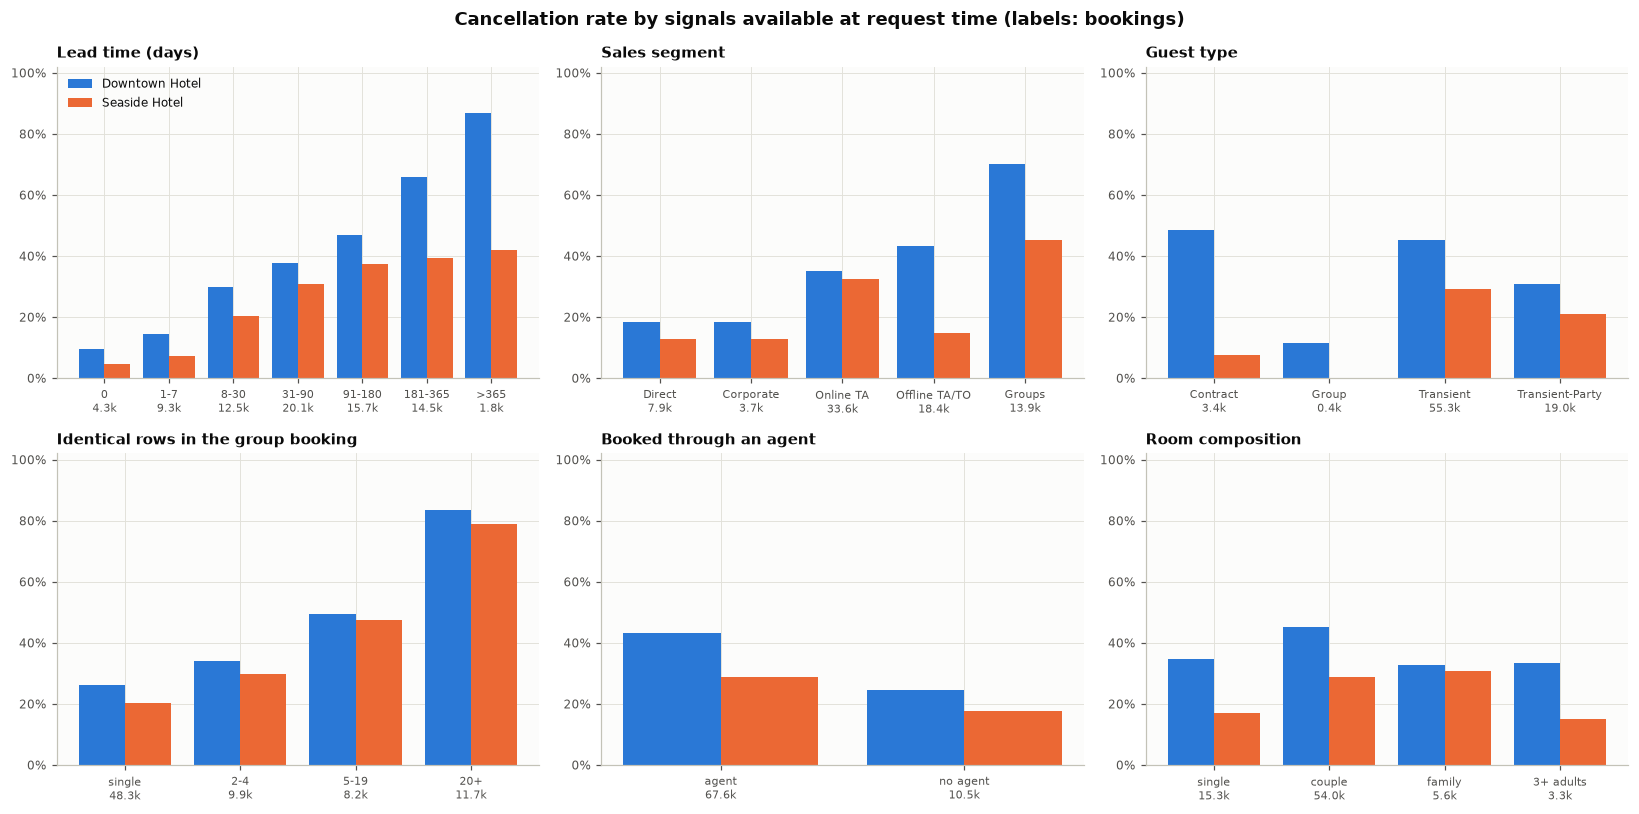

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
rate_by(axes[0, 0], "lead_band", "Lead time (days)", ["0", "1-7", "8-30", "31-90", "91-180", "181-365", ">365"])
rate_by(axes[0, 1], "sales_segment", "Sales segment", ["Direct", "Corporate", "Online TA", "Offline TA/TO", "Groups"])
rate_by(axes[0, 2], "guest_type", "Guest type")
blk = pd.cut(df.block, [0, 1, 4, 19, 10_000], labels=["single", "2-4", "5-19", "20+"]).rename("block")
rate_by(axes[1, 0], blk, "Identical rows in the group booking")
rate_by(axes[1, 1], df.agent.isna().map({True: "no agent", False: "agent"}).rename("ag"), "Booked through an agent")
party = np.select([df.children.fillna(0) + df.babies > 0, df.adults >= 3, df.adults == 2], ["family", "3+ adults", "couple"], "single")
rate_by(axes[1, 2], pd.Series(party, index=df.index, name="party"), "Room composition", ["single", "couple", "family", "3+ adults"])
axes[0, 0].legend()
P.save(fig, "cancellation_drivers")
plt.suptitle("Cancellation rate by signals available at request time (labels: bookings)", fontweight="bold")
plt.tight_layout(); plt.show()

**Lead time is the backbone.** Same-day bookings cancel 5–10% of the time; bookings made more than
a year ahead cancel 87% at Downtown and 42% at Seaside, and the rate rises steadily in between.

**How the booking was sold matters as much.** *Groups* cancel 70% (Downtown) and 45% (Seaside);
*Direct* and *Corporate* only 13–18%. At Downtown the offline tour operators also cancel a lot
(43%), at Seaside they are among the most reliable customers (15%): the same label means different
business in the two hotels, so the model needs the hotel as context.

**Group bookings are the riskiest unit.** Rows that belong to a block of 20+ identical bookings
cancel about 80% of the time at both hotels, against 20–26% for single bookings. Bookings with no
agent cancel less (18–24%) than agency bookings.

### The agent

`agent` is the id of the agency that sold the booking (about 300 ids). A few agencies bring most
of the volume and they behave very differently, so the agent's *historical* cancellation rate is
both a strong feature and an easy explanation ("this agency cancelled 72% of its bookings").

In [3]:
ag = df.assign(agent_id=df.agent.fillna(-1).astype(int).astype(str).replace("-1", "none"))
sc = ag.groupby(["hotel", "agent_id"]).agg(bookings=("cancelled", "size"), cancel_rate=("cancelled", "mean"),
                                           median_lead=("days_ahead", "median"), mean_block=("block", "mean"))
top = sc.sort_values("bookings", ascending=False).groupby("hotel").head(8)
top.round(2)

bookings  cancel_rate  median_lead  mean_block
hotel          agent_id                                                
Downtown Hotel 9            18626         0.39         52.0        1.35
Seaside Hotel  240           8859         0.36         50.0        1.24
Downtown Hotel 1             6808         0.72        276.0       19.87
Seaside Hotel  none          5624         0.18         11.0        3.99
Downtown Hotel none          4889         0.24          7.0       10.73
               7             2111         0.14         44.0        1.19
               6             2068         0.38        247.0       31.49
               14            1966         0.20         35.0        1.26
Seaside Hotel  250           1677         0.16         38.0        1.09
Downtown Hotel 28            1108         0.05         43.0        1.21
               3             1100         0.54        159.0       11.94
Seaside Hotel  241            985         0.12         47.0        1.13
               314            590         0.13         72.5        1.31
               242            478         0.30         63.0        1.17
               40             448         0.05        194.5        1.10
               6              438         0.08         39.5        1.10

One OTA (agent 9 at Downtown, 240 at Seaside) brings over a third of each hotel's volume and
cancels at or above the hotel average (39% and 36%). Behind it, agencies range from 5% (Downtown agent 28) to 72%
(agent 1: blocks of ~20 rooms booked nine months ahead). The model uses both the agent id and its
smoothed historical cancel rate.

## 2 · Strong signals that arrive too late

`special_requests`, `amendments` and `waitlist_days` are among the strongest predictors in the
file. But they accumulate **after** the booking is made: a request that has just arrived has no
amendments yet. Using them would let the model "see the future".

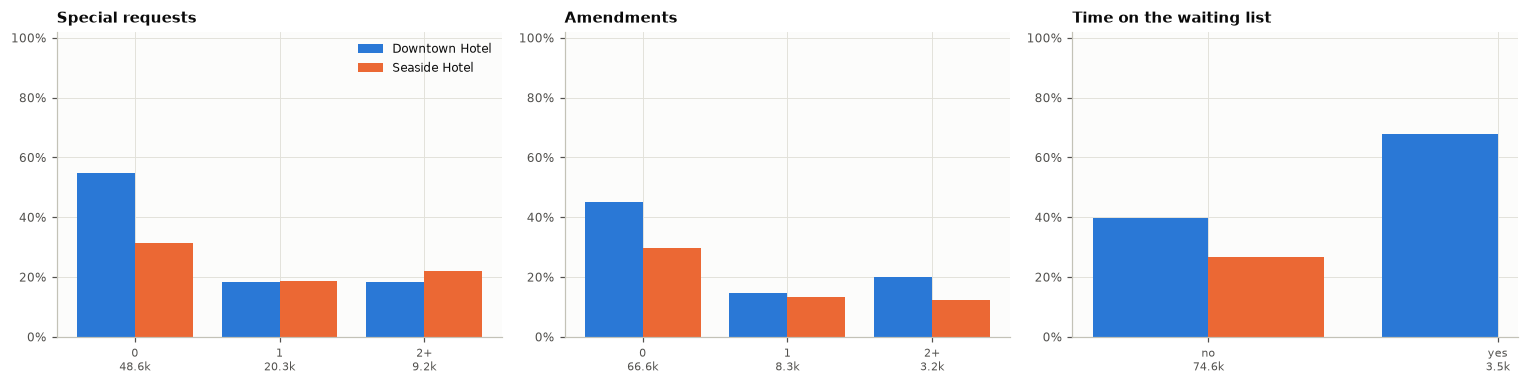

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
rate_by(axes[0], df.special_requests.clip(upper=2).map({0: "0", 1: "1", 2: "2+"}).rename("sr"), "Special requests")
rate_by(axes[1], df.amendments.clip(upper=2).map({0: "0", 1: "1", 2: "2+"}).rename("am"), "Amendments")
rate_by(axes[2], df.waitlist_days.gt(0).map({False: "no", True: "yes"}).rename("wl"), "Time on the waiting list")
axes[0].legend()
plt.tight_layout(); plt.show()

A booking with at least one special request cancels 18% of the time at Downtown, against 55%
without; one amendment cuts the rate from 45% to 15%. These are the strongest signals in the file,
and they are **excluded from the model**: they describe what happened after the request, not the
request. Notebook 07 measures what they would add (about +0.03–0.05 AUC) to show the price of
this honesty.

## 3 · Cancellations come in blocks

38% of the rows are identical to at least one other row: group bookings made together. If the
rooms of a group decided independently, a unanimous outcome (all show up or all cancel) would be
rare for large groups.

In [5]:
raw = [c for c in df.columns if c not in ("booking_id", "cancelled", "value", "block", "lead_band")]
g = df[df.block > 1].groupby(raw, dropna=False).cancelled.agg(n="size", rate="mean")
g["unanimous"] = g.rate.isin([0, 1])
g["band"] = pd.cut(g.n, [1, 2, 4, 9, 19, 10_000], labels=["2", "3-4", "5-9", "10-19", "20+"])
p_all = df.cancelled.mean()
t = g.groupby("band", observed=True).agg(groups=("n", "size"), rows=("n", "sum"), cancel_rate=("rate", "mean"),
                                         unanimous_observed=("unanimous", "mean"))
t["unanimous_if_independent"] = g.groupby("band", observed=True).apply(
    lambda x: (x.rate.mean() ** x.n + (1 - x.rate.mean()) ** x.n).mean(), include_groups=False)
print(f"rows in a group: {(df.block > 1).mean():.1%} · groups with a unanimous outcome: {g.unanimous.mean():.1%}")
t.round(3)

rows in a group: 38.2% · groups with a unanimous outcome: 96.5%


,groups,rows,cancel_rate,unanimous_observed,unanimous_if_independent
band,,,,,
2,3338,6676,0.318,0.979,0.566
3-4,966,3213,0.342,0.958,0.285
5-9,499,3177,0.377,0.940,0.063
10-19,379,5061,0.557,0.926,0.001
20+,370,11690,0.837,0.935,0.013


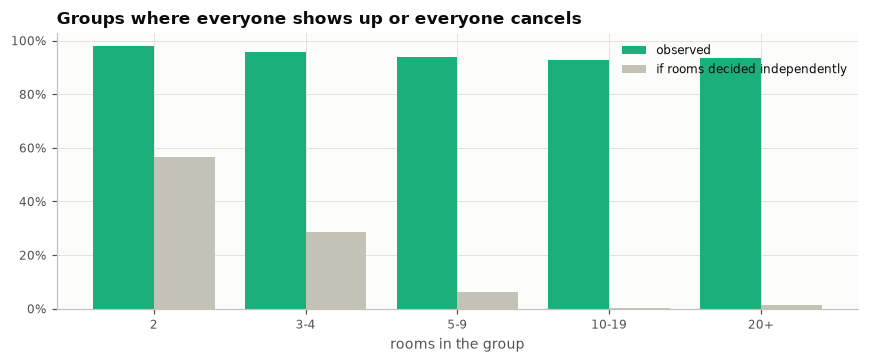

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(t))
ax.bar(x - .2, t.unanimous_observed, .4, color=P.OURS, label="observed")
ax.bar(x + .2, t.unanimous_if_independent, .4, color=P.LIGHT, label="if rooms decided independently")
ax.set_xticks(x, t.index); ax.yaxis.set_major_formatter(P.PCT)
ax.set(title="Groups where everyone shows up or everyone cancels", xlabel="rooms in the group")
ax.legend()
P.save(fig, "groups_unanimous")
plt.tight_layout(); plt.show()

**The outcome of a group is almost always shared.** 38% of rows belong to a group and 96% of the
groups end unanimously; with independent rooms that would happen for barely 1% of groups of ten or
more. Two consequences:

1. The number of guests who show up on a night is much more variable than a sum of independent
   coin flips: a block of 20 rooms is one bet on 0 or 20 guests.
2. Group membership can be **observed live**: when the third identical request arrives, the policy
   knows it is part of a block. The model counts identical and similar requests already seen
   (`block_rank`, `loose_rank`), always in random within-day order (notebook 01).

## 4 · Signals that drift: `country` and guest history

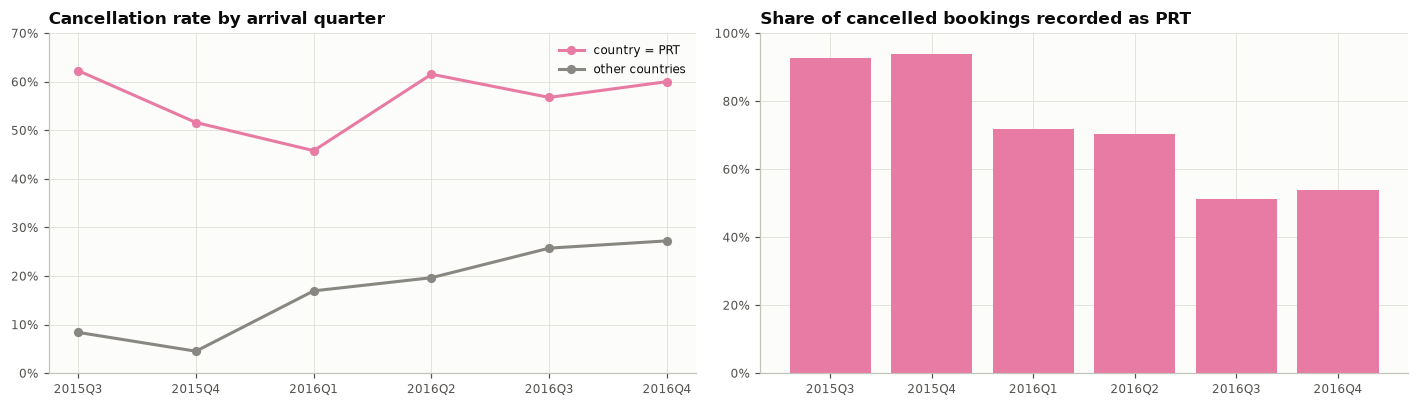

,past_stays,past_cancellations,returning_guest,cancel_if_past_cancel
q,,,,
2015Q3,0.011,0.433,0.024,0.998
2015Q4,0.056,0.229,0.031,0.977
2016Q1,0.195,0.113,0.047,0.904
2016Q2,0.145,0.046,0.024,0.872
2016Q3,0.106,0.017,0.013,0.781
2016Q4,0.181,0.020,0.034,0.629


In [7]:
nd = df.assign(q=df.arrival_date.dt.to_period("Q").astype(str), PRT=df.country.eq("PRT"))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
t = nd.pivot_table(index="q", columns="PRT", values="cancelled", aggfunc="mean")
axes[0].plot(t.index, t[True], marker="o", color=P.MAGENTA, label="country = PRT")
axes[0].plot(t.index, t[False], marker="o", color=P.MUTED, label="other countries")
axes[0].set(title="Cancellation rate by arrival quarter", ylim=(0, .7)); axes[0].yaxis.set_major_formatter(P.PCT)
axes[0].legend()
t = nd[nd.cancelled == 1].groupby("q").PRT.mean()
axes[1].bar(t.index, t, color=P.MAGENTA)
axes[1].set(title="Share of cancelled bookings recorded as PRT", ylim=(0, 1)); axes[1].yaxis.set_major_formatter(P.PCT)
P.save(fig, "country_drift")
plt.tight_layout(); plt.show()
nd.groupby("q").agg(past_stays=("past_stays", "mean"), past_cancellations=("past_cancellations", "mean"),
                    returning_guest=("returning_guest", "mean"),
                    cancel_if_past_cancel=("cancelled", lambda s: s[nd.loc[s.index, "past_cancellations"] > 0].mean())).round(3)

**`country` is partly filled in after the fact.** In 2015, 93–94% of cancelled bookings are
recorded as Portugal (PRT); by the end of 2016 the share is about half. The likely mechanism: the
country is confirmed at check-in, and guests who never arrive keep the default. So "foreign guests
never cancel" holds in 2015 and fades in 2016.

The guest-history counters drift too: `past_cancellations` was high in 2015 (agency blocks that
were re-booked) and almost vanishes in 2016, while the cancel rate of guests with a past
cancellation falls from 99% to 63%.

## 5 · Does a signal keep its meaning over time?

A simple test for every column: learn the cancellation rate of each value (deciles for numeric
columns) on **2015 arrivals**, then measure how well that lookup ranks bookings (AUC) on
(a) other 2015 arrivals (5-fold, same period) and (b) **2016 arrivals**. A column whose AUC falls
sharply from (a) to (b) has changed meaning, and a model trained on it would be miscalibrated in
the following year.

In [8]:
COLS = ["country", "past_cancellations", "past_stays", "returning_guest", "agent", "sales_segment",
        "sales_channel", "guest_type", "days_ahead", "nightly_rate", "nights", "meal", "room_type",
        "block", "special_requests", "amendments"]


NUMERIC = ["days_ahead", "nightly_rate", "nights", "block"]              # deciles fixed on 2015
old, new = df[df.arrival_date.dt.year == 2015], df[df.arrival_date.dt.year == 2016]


def keys(c):
    """Value of column c as a lookup key, for 2015 and 2016 rows."""
    if c in NUMERIC:
        edges = np.unique(np.quantile(old[c], np.linspace(0, 1, 11)))[1:-1]
        return (pd.Series(np.digitize(old[c], edges), index=old.index).astype(str),
                pd.Series(np.digitize(new[c], edges), index=new.index).astype(str))
    f = (lambda s: s.clip(upper=3).astype(str)) if df[c].dtype.kind in "fi" and c != "agent" else (lambda s: s.astype(str))
    return f(old[c]), f(new[c])


rows = []
for c in COLS:
    k_old, k_new = keys(c)
    prior = old.cancelled.mean()
    p_in = np.zeros(len(old))
    for tr, te in KFold(5, shuffle=True, random_state=0).split(old):
        tab = old.cancelled.iloc[tr].groupby(k_old.iloc[tr].values).mean()
        p_in[te] = k_old.iloc[te].map(tab).fillna(prior).to_numpy()
    tab = old.cancelled.groupby(k_old.values).mean()
    p_out = k_new.map(tab).fillna(prior).to_numpy()
    rows.append({"column": c, "AUC within 2015": roc_auc_score(old.cancelled, p_in),
                 "AUC 2015 -> 2016": roc_auc_score(new.cancelled, p_out),
                 "used by the model": c not in ("country", "past_cancellations", "past_stays", "returning_guest",
                                                "special_requests", "amendments")})
drift = pd.DataFrame(rows).set_index("column")
drift["drop"] = drift["AUC within 2015"] - drift["AUC 2015 -> 2016"]
drift.sort_values("drop", ascending=False).round(3)

,AUC within 2015,AUC 2015 -> 2016,used by the model,drop
column,,,,
past_cancellations,0.764,0.533,False,0.231
agent,0.746,0.589,True,0.157
country,0.768,0.675,False,0.093
days_ahead,0.760,0.672,True,0.088
block,0.765,0.684,True,0.080
guest_type,0.507,0.433,True,0.073
nightly_rate,0.622,0.551,True,0.071
sales_segment,0.690,0.623,True,0.068
nights,0.611,0.564,True,0.047


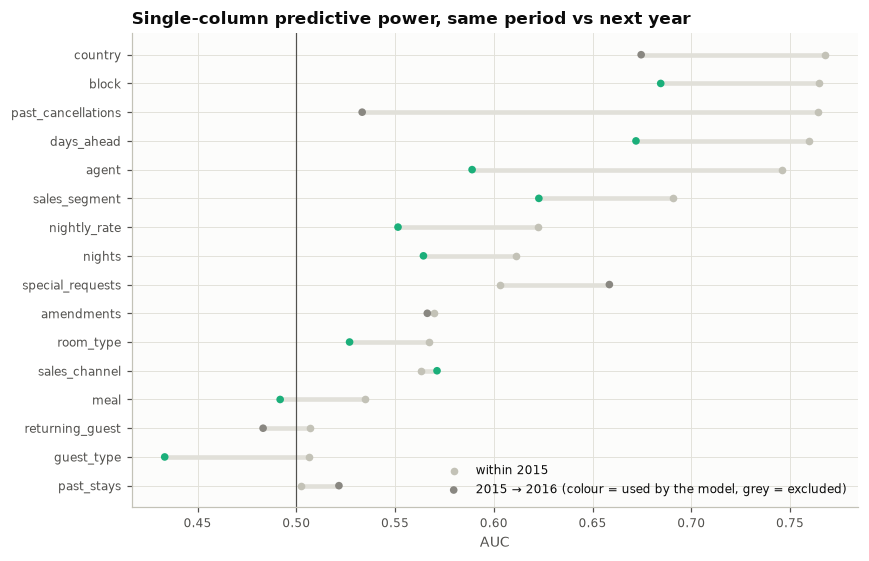

In [9]:
d = drift.sort_values("AUC within 2015")
fig, ax = plt.subplots(figsize=(8, 5.2))
y = np.arange(len(d))
ax.hlines(y, d["AUC 2015 -> 2016"], d["AUC within 2015"], color=P.GRID, lw=3)
ax.scatter(d["AUC within 2015"], y, color=P.LIGHT, label="within 2015", zorder=3)
ax.scatter(d["AUC 2015 -> 2016"], y, color=np.where(d["used by the model"], P.OURS, P.MUTED),
           label="2015 → 2016 (colour = used by the model, grey = excluded)", zorder=3)
ax.set_yticks(y, d.index); ax.axvline(.5, color=P.INK_2, lw=.8)
ax.set(title="Single-column predictive power, same period vs next year", xlabel="AUC")
ax.legend(loc="lower right")
P.save(fig, "signal_drift")
plt.tight_layout(); plt.show()

**Almost every column loses ranking power from 2015 to 2016**, because 2015 was dominated by
agency blocks that cancel en masse and 2016 by online bookings. This is why the model weights recent
months more (half-life 6 months) and why validation must be temporal.

Two columns stand out:

* `past_cancellations` goes from AUC 0.76 to 0.53, close to random: it is excluded.
* `country` keeps some ranking power, but its *level* moves (the PRT share of cancellations halves).
  Ranking is not enough here: the policy needs calibrated probabilities. Notebook 07 shows that
  adding `country` and the history counters makes the January-cut predictions average 11% for a
  true rate of 31%, and more than doubles the log-loss of LightGBM. They are excluded.

`agent` also drifts (new agencies appear, old block agencies shrink). It stays in the model, with
smoothing towards the overall rate for small agencies and with recency weights.

## Takeaways

| Signal | Strength | Usable? | How the system uses it |
|---|---|---|---|
| Lead time | strong, monotone | yes | log lead + lead band |
| Segment, channel, guest type, hotel | strong, hotel-specific | yes | categorical features |
| Agent | strong, drifting | yes | id + smoothed historical rate, recency weights |
| Group of identical requests | strong, outcomes shared | yes, online | counters of identical / similar requests seen so far |
| Special requests, amendments, waitlist | very strong | **no**, post-booking | excluded |
| Country, guest history | strong in 2015, drifting | **no**, breaks calibration | excluded |
| `deposit` | near perfect | **no**, organisers' rule | excluded |